Requires numpy and matplotlib.

In [115]:
from pathlib import Path
import sys

repo = Path().cwd().parent
sys.path.insert(0, str(repo / "src"))

from golemLLM.core.client import GolemCLIENThttp
from golemLLM.parsing import getShotJSONfield

def parse_waveform(text: str) -> list[tuple[float, float]]:
    """Parses a 'time,value;time,value;...' waveform string into (time, value) float pairs."""
    pairs = []
    for item in text.split(";"):
        item = item.strip()
        if not item:
            continue
        t, v = item.split(",")
        pairs.append((float(t), float(v)))
    return pairs
def last_sample(text: str) -> tuple[float, float]:
    """(time, value) of the sample farthest in time in a waveform string. Raises ValueError if it has no samples."""
    pairs = parse_waveform(text)
    if not pairs:
        raise ValueError("Waveform has no samples.")
    return max(pairs, key=lambda pair: pair[0])

client = GolemCLIENThttp("http://golem.fjfi.cvut.cz/shots", cache=True)

In [116]:
import time

WAVEFORM_FIELDS = {
    "radial": "parameters/infrastructure.position_stabilization/radial_waveform",
    "vertical": "parameters/infrastructure.position_stabilization/vertical_waveform",
    "current": "parameters/infrastructure.current_stabilization/waveform",
}

endings = {}  # (shot, waveform name) -> (time [µs], voltage) of the sample farthest in time

for shot in range(54650, 54785+1, 1):
    for name, field in WAVEFORM_FIELDS.items():
        try:
            text = getShotJSONfield(client, shot, "conductor/discharge.json", field)
            endings[(shot, name)] = last_sample(text)
        except Exception as e:
            print(f"Shot {shot} {name}: {e}")
    time.sleep(0.5)

print(f"Endings: {endings}")

Shot 54650 radial: 'infrastructure.position_stabilization'
Shot 54650 vertical: 'infrastructure.position_stabilization'
Shot 54650 current: 'infrastructure.current_stabilization'
Shot 54651 radial: 'infrastructure.position_stabilization'
Shot 54651 vertical: 'infrastructure.position_stabilization'
Shot 54651 current: 'infrastructure.current_stabilization'
Shot 54652 radial: 'infrastructure.position_stabilization'
Shot 54652 vertical: 'infrastructure.position_stabilization'
Shot 54652 current: 'infrastructure.current_stabilization'
Shot 54653 radial: 'infrastructure.position_stabilization'
Shot 54653 vertical: 'infrastructure.position_stabilization'
Shot 54653 current: 'infrastructure.current_stabilization'
Shot 54654 radial: 'infrastructure.position_stabilization'
Shot 54654 vertical: 'infrastructure.position_stabilization'
Shot 54654 current: 'infrastructure.current_stabilization'
Shot 54655 radial: 'infrastructure.position_stabilization'
Shot 54655 vertical: 'infrastructure.position_

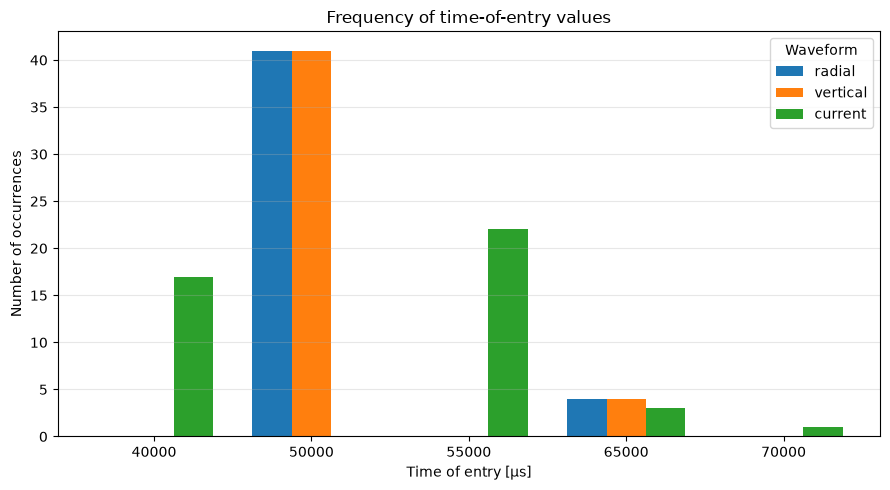

In [ ]:
from collections import Counter

counts = {
    name: Counter(
        t for (shot, waveform_name), (t, voltage) in endings.items()
        if waveform_name == name
    )
    for name in names
}

times = sorted({t for counter in counts.values() for t in counter})
x = range(len(times))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

for i, name in enumerate(names):
    offsets = [j + (i - 1) * width for j in x]
    ax.bar(
        offsets,
        [counts[name].get(t, 0) for t in times],
        width=width,
        label=name,
    )

ax.set_xticks(list(x))
ax.set_xticklabels([f"{t:g}" for t in times])
ax.set_xlabel("Time of entry [µs]")
ax.set_ylabel("Number of occurrences")
ax.set_title("Last specified values of waveforms in shots")
ax.legend(title="Waveform")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()